In [ ]:
# Task 1 — Data Import & Setup

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("social_media_engagement_5000.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
import os

print(os.getcwd())
print(os.listdir())

C:\Users\HP\Documents\Data Analytics\Module end assignment pandas
['.ipynb_checkpoints', 'Social Media Engagement Analytics.ipynb', 'social_media_engagement_5000.csv']


In [6]:
# Convert date columns to datetime
df['posted_at'] = pd.to_datetime(
    df['posted_at'],
    format='%d-%m-%Y',
    errors='coerce'
)

print(df[['posted_at']].head())
print(df.dtypes)

   posted_at
0 2022-12-17
1 2023-06-02
2 2023-05-07
3 2023-02-12
4 2023-05-23
user_id                      int64
age                        float64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
dtype: object


In [8]:
#Use NumPy arrays for basic array operations
likes_array = df['likes'].dropna().to_numpy()

print("First 5 likes:", likes_array[:5])
print("Total likes:", np.sum(likes_array))
print("Average likes:", np.mean(likes_array))
print("Maximum likes:", np.max(likes_array))
print("Minimum likes:", np.min(likes_array))

First 5 likes: [ 7011. 11750.  4862.  5350. 12682.]
Total likes: 49019162.0
Average likes: 10107.043711340206
Maximum likes: 19998.0
Minimum likes: 10.0


In [9]:
# Task 2 — Data Cleaning
#Cleaning Missing Data
# Count missing values in each column
print(df.isnull().sum())

# Show only columns containing missing values
missing = df.isnull().sum()
display(missing[missing > 0].to_frame('Missing Values'))

# Calculate missing percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100
display(missing_percentage[missing_percentage > 0].to_frame(
    'Missing Percentage'
).round(2))

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64


,Missing Values
age,150
gender,150
likes,150
comments,150
shares,150
sentiment,150


,Missing Percentage
age,3.0
gender,3.0
likes,3.0
comments,3.0
shares,3.0
sentiment,3.0


In [11]:
# Remove duplicate records
print("Duplicates before cleaning:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates after cleaning:", df.duplicated().sum())

Duplicates before cleaning: 0
Duplicates after cleaning: 0


In [12]:
# Handle missing values
# Work on a copy
df_clean = df.copy()

# Numerical columns to fill
numeric_cols = [
    'age', 'likes', 'comments', 'shares'
]

for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

# Categorical columns to fill
categorical_cols = ['gender', 'sentiment']

for col in categorical_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].mode()[0]
    )

print("Missing values after cleaning:")
print(df_clean.isnull().sum())

Missing values after cleaning:
user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64


In [13]:
#Standardize categories (e.g., gender labels)
text_cols = [
    'gender', 'country', 'post_type',
    'post_category', 'device_type', 'sentiment'
]

for col in text_cols:
    df_clean[col] = (
        df_clean[col]
        .astype('string')
        .str.strip()
        .str.lower()
    )

# Check the standardized categories
for col in text_cols:
    print(f"\n{col}:")
    print(df_clean[col].value_counts())



gender:
gender
male      1849
other     1581
female    1570
Name: count, dtype: int64[pyarrow]

country:
country
india        535
canada       513
brazil       504
uae          503
usa          501
france       496
uk           493
australia    493
germany      490
japan        472
Name: count, dtype: int64[pyarrow]

post_type:
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64[pyarrow]

post_category:
post_category
fitness      675
tech         665
music        635
education    631
lifestyle    607
travel       600
fashion      594
food         593
Name: count, dtype: int64[pyarrow]

device_type:
device_type
mobile     1684
tablet     1658
desktop    1658
Name: count, dtype: int64[pyarrow]

sentiment:
sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64[pyarrow]


In [14]:
# Check numerical ranges
check_cols = [
    'age', 'likes', 'comments', 'shares',
    'watch_time_sec', 'impression_count',
    'follower_count', 'engagement_rate'
]

display(df_clean[check_cols].describe().T)

# Check invalid negative values in non-negative metrics
non_negative_cols = [
    'likes', 'comments', 'shares',
    'watch_time_sec', 'impression_count',
    'follower_count', 'engagement_rate'
]

for col in non_negative_cols:
    print(col, "negative values:", (df_clean[col] < 0).sum())

# Check age range
print("Age below 13:", (df_clean['age'] < 13).sum())
print("Age above 100:", (df_clean['age'] > 100).sum())

,count,mean,std,min,25%,50%,75%,max
age,5000.0,38.440400,14.687151,13.000000,26.000000,38.000000,51.000000,64.000000
likes,5000.0,10106.997400,5702.293017,10.000000,5235.000000,10105.500000,14959.000000,19998.000000
comments,5000.0,1502.039800,856.393312,0.000000,792.000000,1497.000000,2235.250000,2999.000000
shares,5000.0,1002.910600,570.855200,0.000000,511.000000,1012.000000,1483.000000,1999.000000
watch_time_sec,5000.0,4014.503200,2308.096459,0.000000,2017.750000,4034.500000,6020.250000,7998.000000
impression_count,5000.0,50013.732800,28844.939104,105.000000,24988.250000,49934.500000,74662.250000,99995.000000
follower_count,5000.0,393698.224800,230927.884535,87.000000,194480.000000,388982.000000,589744.250000,799533.000000
engagement_rate,5000.0,0.964356,5.318029,0.006363,0.145781,0.253896,0.504794,191.504348


likes negative values: 0
comments negative values: 0
shares negative values: 0
watch_time_sec negative values: 0
impression_count negative values: 0
follower_count negative values: 0
engagement_rate negative values: 0
Age below 13: 0
Age above 100: 0


In [15]:
# Check the range of numerical metrics
check_cols = [
    'age',
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'impression_count',
    'follower_count',
    'engagement_rate'
]

display(df_clean[check_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
age,5000.0,38.440400,14.687151,13.000000,26.000000,38.000000,51.000000,64.000000
likes,5000.0,10106.997400,5702.293017,10.000000,5235.000000,10105.500000,14959.000000,19998.000000
comments,5000.0,1502.039800,856.393312,0.000000,792.000000,1497.000000,2235.250000,2999.000000
shares,5000.0,1002.910600,570.855200,0.000000,511.000000,1012.000000,1483.000000,1999.000000
watch_time_sec,5000.0,4014.503200,2308.096459,0.000000,2017.750000,4034.500000,6020.250000,7998.000000
impression_count,5000.0,50013.732800,28844.939104,105.000000,24988.250000,49934.500000,74662.250000,99995.000000
follower_count,5000.0,393698.224800,230927.884535,87.000000,194480.000000,388982.000000,589744.250000,799533.000000
engagement_rate,5000.0,0.964356,5.318029,0.006363,0.145781,0.253896,0.504794,191.504348


In [16]:
#Feature Cleaning
#Extract hashtag count
df_clean['hashtag_count'] = (
    df_clean['hashtags']
    .fillna('')
    .str.findall(r'#\w+')
    .str.len()
)

display(df_clean[['hashtags', 'hashtag_count']].head(10))

,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1
5,#fitness,1
6,#music,1
7,#travel #music #fitness,3
8,#music #fun #fitness,3
9,#lifestyle #love,2


In [17]:
#Clean sentiment labels
df_clean['sentiment'] = (
    df_clean['sentiment']
    .str.strip()
    .str.lower()
)

print(df_clean['sentiment'].value_counts())

sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64[pyarrow]


In [18]:
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("Total missing values:", df_clean.isnull().sum().sum())
print("Total duplicate rows:", df_clean.duplicated().sum())

display(df_clean.head())

Original dataset shape: (5000, 19)
Cleaned dataset shape: (5000, 20)
Total missing values: 0
Total duplicate rows: 0


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,female,brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33.0,male,brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32.0,female,uk,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51.0,other,france,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34.0,other,uk,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372,1


In [19]:
#Task 3 — Data Exploration using Pandas
#View dataset structure using head(), tail(), shape, and columns.
# 1. First five rows
print("First five rows:")
display(df.head())

# 2. Last five rows
print("Last five rows:")
display(df.tail())

# 3. Dataset dimensions
print("\nDataset dimensions:", df.shape)

# 4. Column names
print("\nColumn names:")
print(df.columns.tolist())

First five rows:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372


Last five rows:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,NaN,167.0,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518
4999,73400,54.0,Other,Japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527



Dataset dimensions: (5000, 19)

Column names:
['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate']


In [4]:
#Check the dataset size
print("Number of rows and columns:", df.shape)

Number of rows and columns: (5000, 19)


In [5]:
#Check the data types and information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   str    
 3   country           5000 non-null   str    
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   str    
 6   post_category     5000 non-null   str    
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   str    
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   str    
 16  sentiment         4850 non-null   str    
 17  hashta

In [6]:
df.dtypes

user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object

In [7]:
#Generate summary statistics using describe().
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate
count,5000.000000,4850.000000,5000.000000,4850.000000,4850.000000,4850.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.454021,548042.909000,10107.043711,1502.195670,1002.629485,4014.503200,50013.732800,393698.224800,0.964356
std,26090.370121,14.912381,260646.957267,5789.819252,869.537889,579.615158,2308.096459,28844.939104,230927.884535,5.318029
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.000000,0.000000,105.000000,87.000000,0.006363
25%,32309.500000,26.000000,322543.500000,5068.500000,760.000000,498.000000,2017.750000,24988.250000,194480.000000,0.145781
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.000000,4034.500000,49934.500000,388982.000000,0.253896
75%,77180.500000,51.000000,771574.500000,15115.000000,2256.000000,1501.000000,6020.250000,74662.250000,589744.250000,0.504794
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.000000,7998.000000,99995.000000,799533.000000,191.504348


In [20]:
#Analyze categorical distributions using value_counts(), unique(), and nunique()
print("Post types:")
print(df_clean['post_type'].value_counts())

print("\nPost categories:")
print(df_clean['post_category'].value_counts())

print("\nUnique countries:")
print(df_clean['country'].unique())

print("\nNumber of unique countries:",
      df_clean['country'].nunique())

Post types:
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64[pyarrow]

Post categories:
post_category
fitness      675
tech         665
music        635
education    631
lifestyle    607
travel       600
fashion      594
food         593
Name: count, dtype: int64[pyarrow]

Unique countries:
<ArrowStringArray>
[   'brazil',        'uk',    'france',    'canada',     'japan', 'australia',
     'india',       'uae',   'germany',       'usa']
Length: 10, dtype: string

Number of unique countries: 10


In [22]:
#Correlation matrix
numeric_df = df_clean.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr()

display(correlation_matrix.round(2))

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
user_id,1.00,-0.01,0.02,0.03,-0.03,0.01,-0.02,0.02,0.01,-0.00,-0.01
age,-0.01,1.00,-0.01,-0.04,-0.01,0.01,0.01,0.01,-0.02,0.01,0.01
post_id,0.02,-0.01,1.00,0.01,-0.01,0.00,0.02,-0.01,-0.00,0.01,0.01
likes,0.03,-0.04,0.01,1.00,-0.02,0.00,0.01,0.01,-0.02,0.09,-0.00
comments,-0.03,-0.01,-0.01,-0.02,1.00,0.01,-0.02,-0.01,-0.01,0.00,-0.02
shares,0.01,0.01,0.00,0.00,0.01,1.00,0.01,-0.01,-0.01,0.02,0.01
watch_time_sec,-0.02,0.01,0.02,0.01,-0.02,0.01,1.00,-0.00,0.00,-0.00,-0.02
impression_count,0.02,0.01,-0.01,0.01,-0.01,-0.01,-0.00,1.00,-0.02,-0.23,-0.00
follower_count,0.01,-0.02,-0.00,-0.02,-0.01,-0.01,0.00,-0.02,1.00,0.00,0.01
engagement_rate,-0.00,0.01,0.01,0.09,0.00,0.02,-0.00,-0.23,0.00,1.00,0.01


In [23]:
#Use groupby() to summarize metrics (e.g., avg likes by post type, impressions by country).
avg_likes_by_type = (
    df_clean.groupby('post_type')['likes']
    .mean()
    .sort_values(ascending=False)
)

display(avg_likes_by_type.to_frame('Average Likes').round(2))

,Average Likes
post_type,
video,10188.60
image,10104.87
text,10100.15
reel,10037.80


In [25]:
country_engagement = (
    df_clean.groupby('country')['engagement_rate']
    .mean()
    .sort_values(ascending=False)
)

display(country_engagement.to_frame(
    'Average Engagement Rate'
).round(3))

,Average Engagement Rate
country,
brazil,1.541
australia,1.324
france,1.146
uae,1.112
canada,0.917
uk,0.851
japan,0.770
germany,0.759
india,0.655


In [24]:
impressions_by_country = (
    df_clean.groupby('country')['impression_count']
    .mean()
    .sort_values(ascending=False)
)

display(impressions_by_country.to_frame(
    'Average Impressions'
).round(2))

,Average Impressions
country,
india,52462.39
france,51727.67
usa,51263.87
uk,51119.39
japan,49616.14
brazil,49193.17
uae,48928.41
canada,48703.15
germany,48605.41


In [26]:
#Task 4 — Data Wrangling 
df_clean['engagement_score'] = (
    df_clean['likes']
    + df_clean['comments']
    + df_clean['shares']
)

display(df_clean[
    ['likes', 'comments', 'shares', 'engagement_score']
].head())

,likes,comments,shares,engagement_score
0,7011.0,354.0,1157.0,8522.0
1,11750.0,2606.0,1807.0,16163.0
2,4862.0,344.0,955.0,6161.0
3,5350.0,1083.0,1049.0,7482.0
4,12682.0,2735.0,1300.0,16717.0


In [27]:
df_clean['log_likes'] = np.log1p(df_clean['likes'])
df_clean['log_impressions'] = np.log1p(
    df_clean['impression_count']
)

display(df_clean[
    ['likes', 'log_likes',
     'impression_count', 'log_impressions']
].head())

,likes,log_likes,impression_count,log_impressions
0,7011.0,8.855378,44650,10.706632
1,11750.0,9.371694,80216,11.292491
2,4862.0,8.489411,44858,10.711280
3,5350.0,8.585039,70455,11.162744
4,12682.0,9.448018,6019,8.702843


In [28]:
category_summary = df_clean.groupby('post_category').agg(
    total_posts=('post_id', 'count'),
    average_likes=('likes', 'mean'),
    average_comments=('comments', 'mean'),
    average_shares=('shares', 'mean'),
    average_engagement=('engagement_rate', 'mean')
).sort_values('average_engagement', ascending=False)

display(category_summary.round(2))

,total_posts,average_likes,average_comments,average_shares,average_engagement
post_category,,,,,
food,593,10225.52,1510.88,1002.80,1.36
tech,665,10171.57,1505.55,1009.37,1.16
lifestyle,607,10180.56,1467.84,991.14,1.09
music,635,10205.75,1558.71,1024.09,0.89
fitness,675,9914.60,1501.14,1042.05,0.87
education,631,10126.49,1455.34,996.45,0.84
fashion,594,9843.36,1530.54,982.52,0.81
travel,600,10196.30,1485.95,968.31,0.70


In [29]:
sentiment_summary = df_clean.groupby('sentiment').agg(
    total_posts=('post_id', 'count'),
    average_likes=('likes', 'mean'),
    average_comments=('comments', 'mean'),
    average_watch_time=('watch_time_sec', 'mean'),
    average_engagement=('engagement_rate', 'mean')
)

display(sentiment_summary.round(2))

,total_posts,average_likes,average_comments,average_watch_time,average_engagement
sentiment,,,,,
negative,960,10208.10,1516.09,4054.64,1.04
neutral,1527,9923.19,1528.40,4031.82,0.99
positive,2513,10180.06,1480.65,3988.65,0.92


In [30]:
# Task 5 — Statistical analysis
stats_cols = [
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'engagement_rate',
    'follower_count'
]

statistics = pd.DataFrame(index=stats_cols)

statistics['Mean'] = df_clean[stats_cols].mean()
statistics['Median'] = df_clean[stats_cols].median()
statistics['Mode'] = df_clean[stats_cols].mode().iloc[0]
statistics['Standard Deviation'] = df_clean[stats_cols].std()
statistics['Variance'] = df_clean[stats_cols].var()
statistics['25th Percentile'] = df_clean[stats_cols].quantile(0.25)
statistics['75th Percentile'] = df_clean[stats_cols].quantile(0.75)

display(statistics.round(2))

,Mean,Median,Mode,Standard Deviation,Variance,25th Percentile,75th Percentile
likes,10107.00,10105.50,10105.50,5702.29,3.251615e+07,5235.00,14959.00
comments,1502.04,1497.00,1497.00,856.39,7.334095e+05,792.00,2235.25
shares,1002.91,1012.00,1012.00,570.86,3.258757e+05,511.00,1483.00
watch_time_sec,4014.50,4034.50,916.00,2308.10,5.327309e+06,2017.75,6020.25
engagement_rate,0.96,0.25,0.01,5.32,2.828000e+01,0.15,0.50
follower_count,393698.22,388982.00,497502.00,230927.88,5.332769e+10,194480.00,589744.25


In [31]:
print("Skewness:")
display(df_clean[stats_cols].skew().to_frame('Skewness').round(2))

print("Kurtosis:")
display(df_clean[stats_cols].kurt().to_frame('Kurtosis').round(2))

Skewness:


,Skewness
likes,-0.01
comments,0.00
shares,-0.01
watch_time_sec,-0.02
engagement_rate,18.78
follower_count,0.04


Kurtosis:


,Kurtosis
likes,-1.15
comments,-1.14
shares,-1.15
watch_time_sec,-1.20
engagement_rate,482.99
follower_count,-1.19


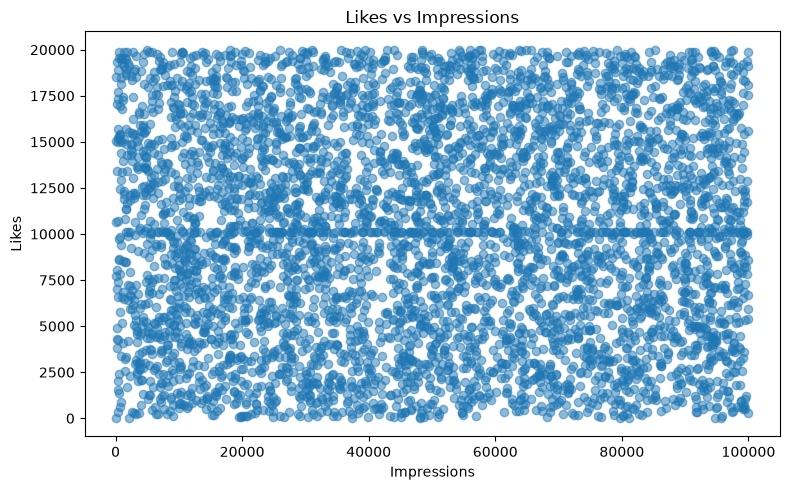

In [32]:
#Task 6 — Data visualization
#Matplotlib
#Scatter plot: Likes vs. impressions
plt.figure(figsize=(8, 5))

plt.scatter(
    df_clean['impression_count'],
    df_clean['likes'],
    alpha=0.5
)

plt.title('Likes vs Impressions')
plt.xlabel('Impressions')
plt.ylabel('Likes')
plt.tight_layout()
plt.show()

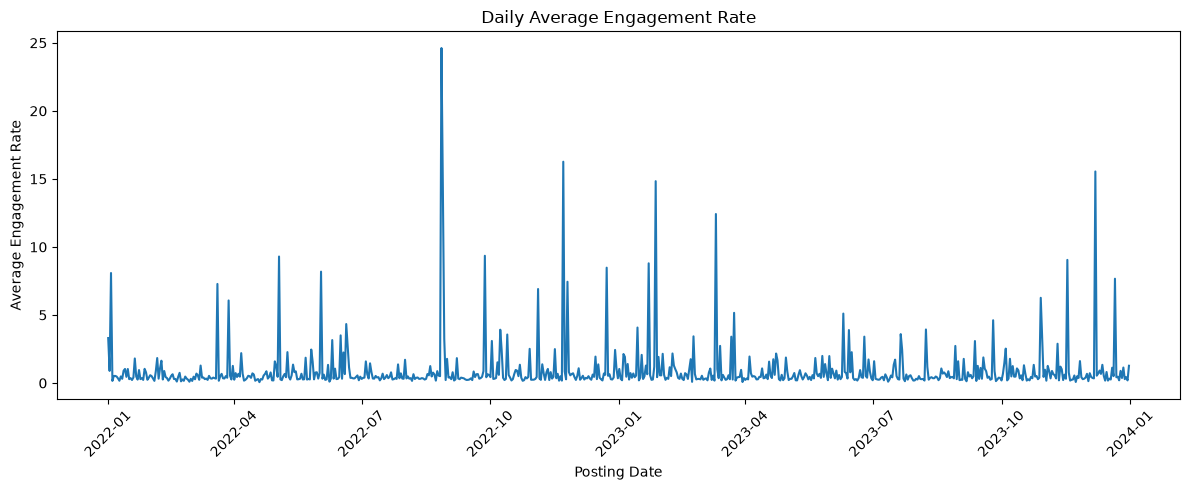

In [33]:
#Line chart: Daily engagement 
daily_engagement = (
    df_clean.groupby('posted_at')['engagement_rate']
    .mean()
    .sort_index()
)

plt.figure(figsize=(12, 5))
plt.plot(daily_engagement.index, daily_engagement.values)

plt.title('Daily Average Engagement Rate')
plt.xlabel('Posting Date')
plt.ylabel('Average Engagement Rate')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

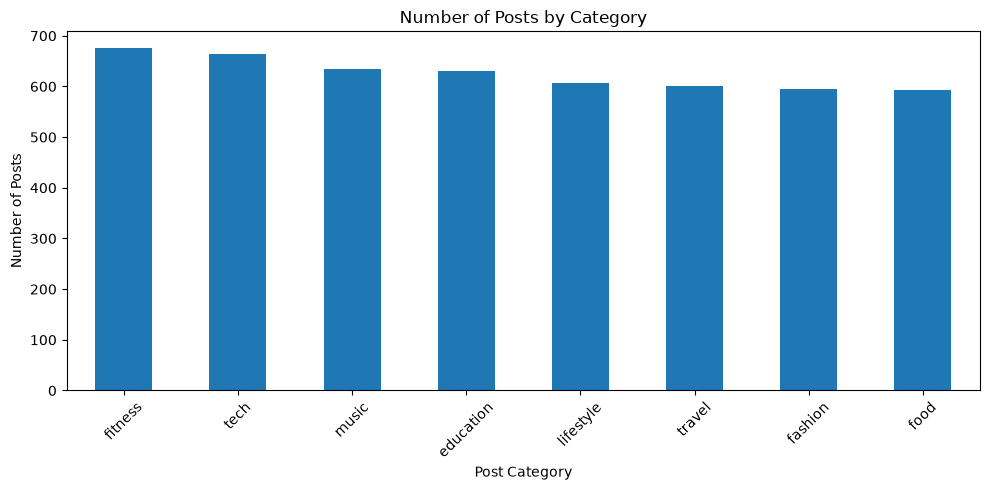

In [36]:
# Plot 3 — Bar chart: Number of posts by category
posts_by_category = df_clean['post_category'].value_counts()

plt.figure(figsize=(10, 5))
posts_by_category.plot(kind='bar')

plt.title('Number of Posts by Category')
plt.xlabel('Post Category')
plt.ylabel('Number of Posts')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

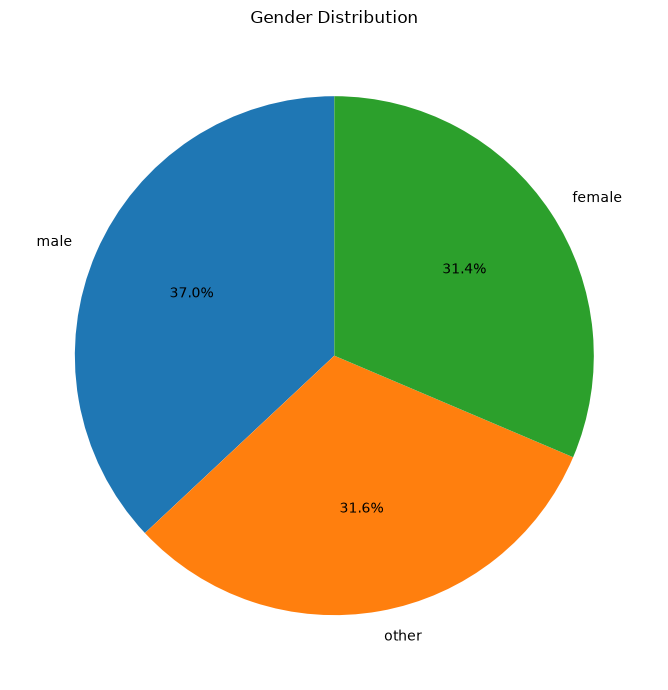

In [38]:
# Pie chart: Gender distribution
gender_counts = df_clean['gender'].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Gender Distribution')
plt.tight_layout()
plt.show()

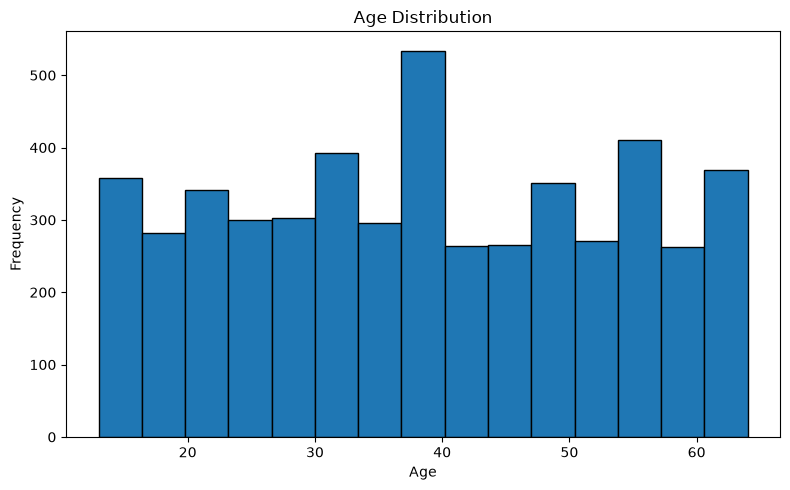

In [39]:
# Histogram: Age distribution
plt.figure(figsize=(8, 5))

plt.hist(df_clean['age'], bins=15, edgecolor='black')

plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

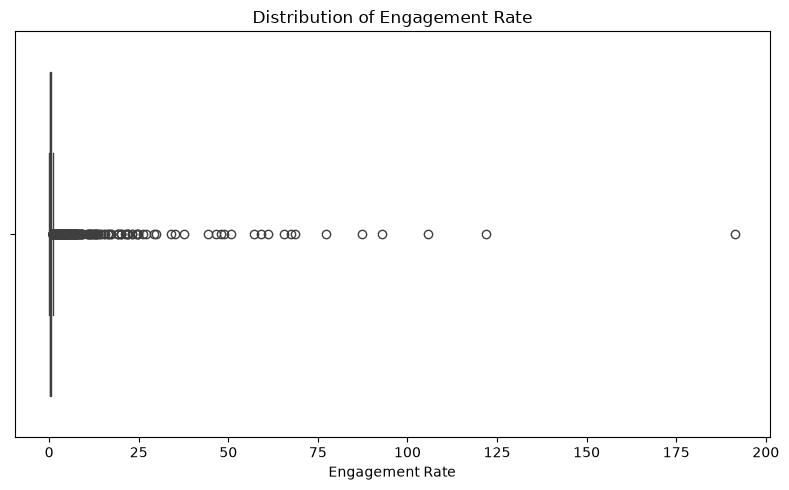

In [40]:
# Box plot: Engagement rate
plt.figure(figsize=(8, 5))

sns.boxplot(x=df_clean['engagement_rate'])

plt.title('Distribution of Engagement Rate')
plt.xlabel('Engagement Rate')
plt.tight_layout()
plt.show()

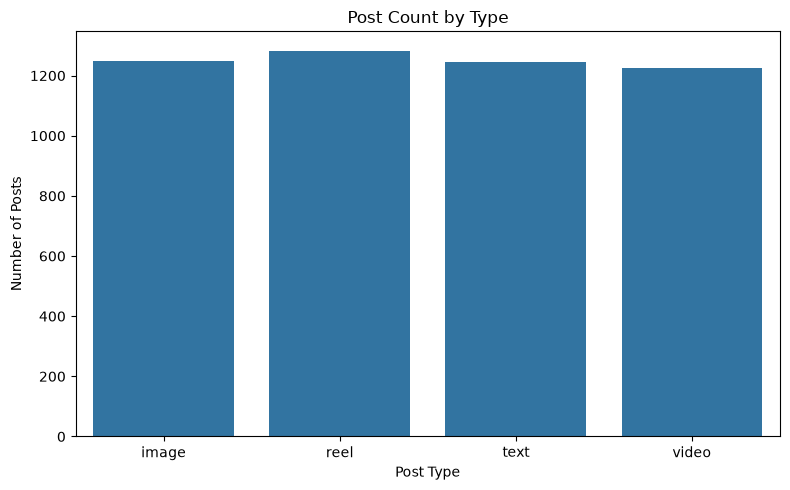

In [41]:
#Seaborn
#count plot: Post type
plt.figure(figsize=(8, 5))

sns.countplot(data=df_clean, x='post_type')

plt.title('Post Count by Type')
plt.xlabel('Post Type')
plt.ylabel('Number of Posts')
plt.tight_layout()
plt.show()

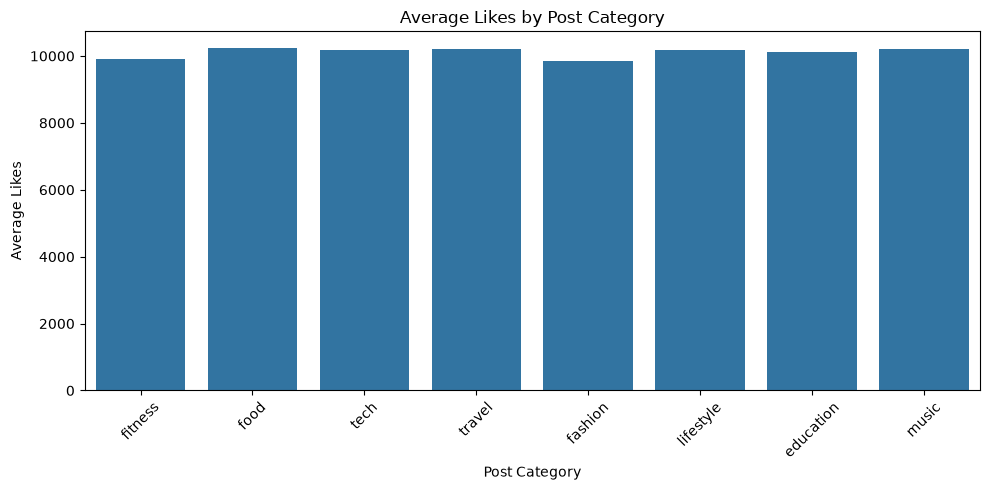

In [42]:
# bar plot: Average likes by category
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df_clean,
    x='post_category',
    y='likes',
    errorbar=None
)

plt.title('Average Likes by Post Category')
plt.xlabel('Post Category')
plt.ylabel('Average Likes')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

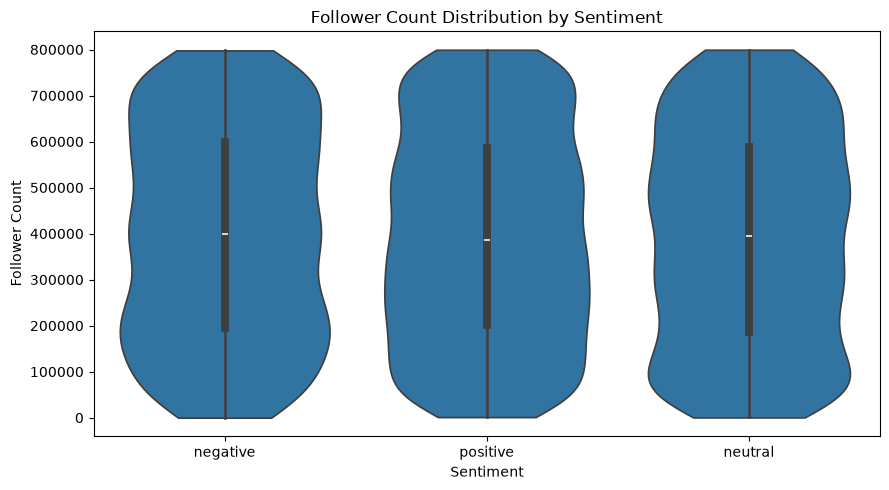

In [44]:
# Violin plot: Followers vs. sentiment
plt.figure(figsize=(9, 5))

sns.violinplot(
    data=df_clean,
    x='sentiment',
    y='follower_count',
    cut=0
)

plt.title('Follower Count Distribution by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Follower Count')
plt.tight_layout()
plt.show()

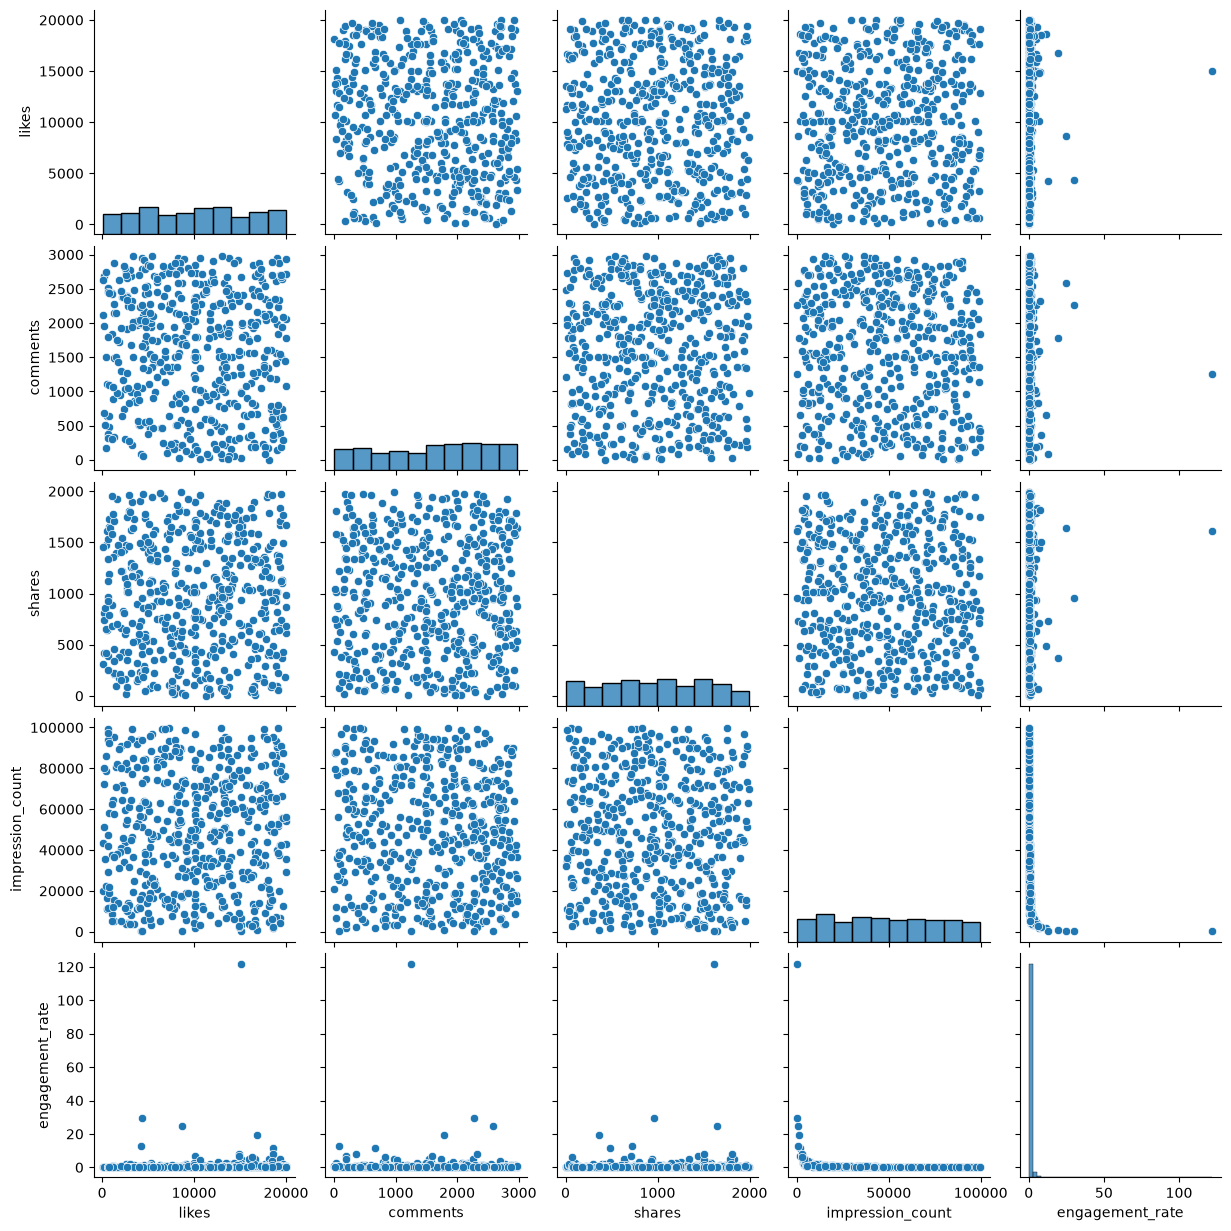

In [45]:
#Pair plot: Numeric features
pair_cols = [
    'likes',
    'comments',
    'shares',
    'impression_count',
    'engagement_rate'
]

sns.pairplot(
    df_clean[pair_cols].sample(
        n=min(500, len(df_clean)),
        random_state=42
    ).dropna()
)

plt.show()

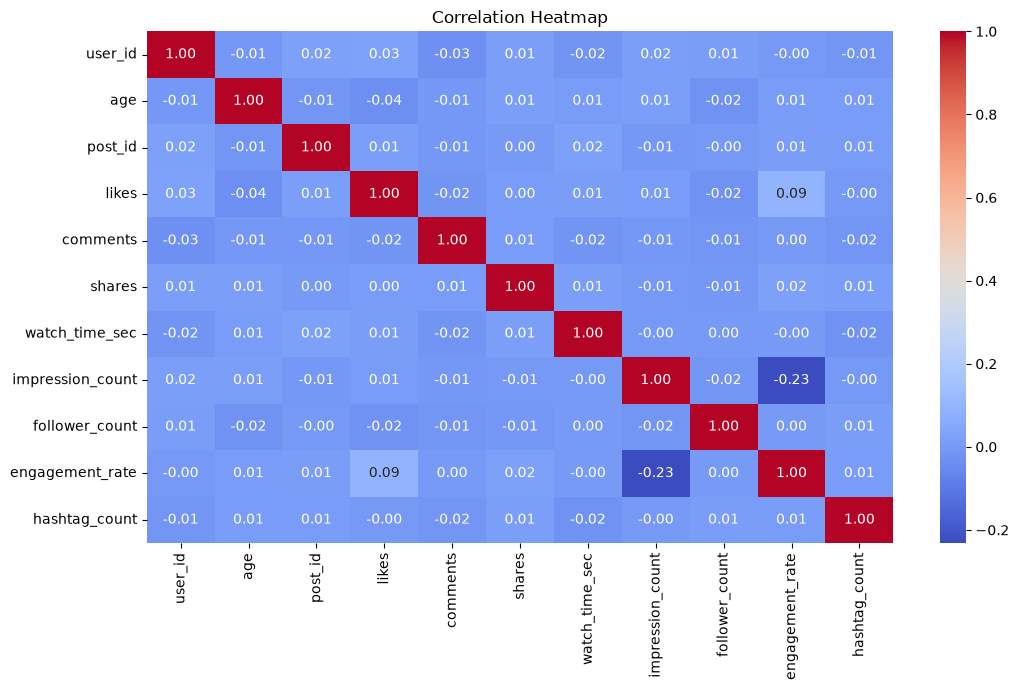

In [46]:
# Heatmap: Correlation matrix
plt.figure(figsize=(11, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

C:\Users\HP\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 5.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\HP\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 30.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\HP\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 25.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\HP\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 15.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\HP\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 37.9% of the points cannot be place

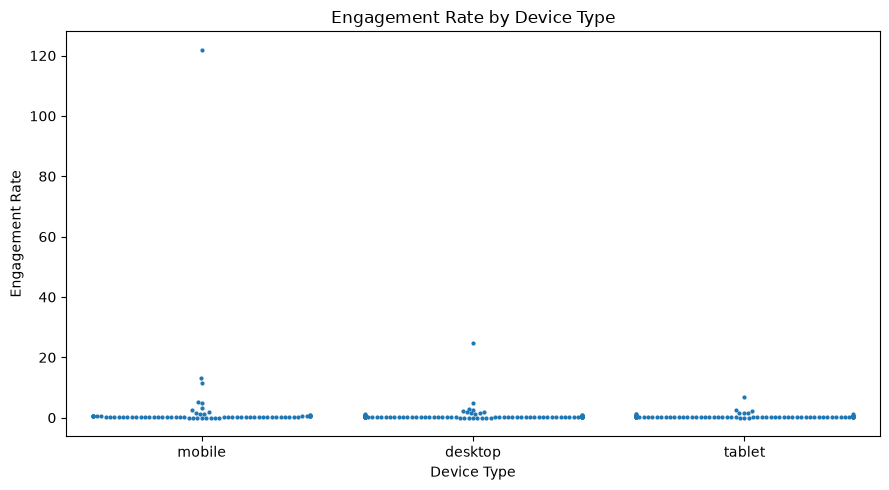

In [47]:
#Swarm plot: Engagement vs. device
swarm_data = df_clean.sample(
    n=min(250, len(df_clean)),
    random_state=42
)

plt.figure(figsize=(9, 5))

sns.swarmplot(
    data=swarm_data,
    x='device_type',
    y='engagement_rate',
    size=3
)

plt.title('Engagement Rate by Device Type')
plt.xlabel('Device Type')
plt.ylabel('Engagement Rate')
plt.tight_layout()
plt.show()

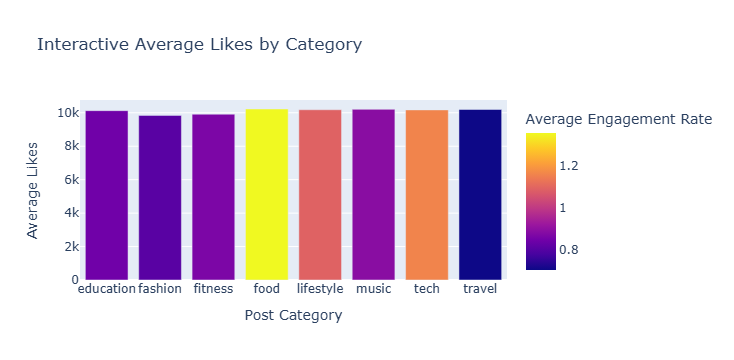

In [69]:
#Plotly (Interactive)
#Interactive line chart/bar chart/bubble/scatter chart
import plotly.express as px

interactive_data = df_clean.groupby('post_category', as_index=False).agg(
    average_likes=('likes', 'mean'),
    average_engagement=('engagement_rate', 'mean')
)

fig = px.bar(
    interactive_data,
    x='post_category',
    y='average_likes',
    color='average_engagement',
    title='Interactive Average Likes by Category',
    labels={
        'post_category': 'Post Category',
        'average_likes': 'Average Likes',
        'average_engagement': 'Average Engagement Rate'
    },
    hover_data=['average_engagement']
)

fig.show()


In [51]:
#Which post type has the highest engagement?
post_type_results = (
    df_clean.groupby('post_type')
    .agg(
        average_engagement=('engagement_rate', 'mean'),
        average_likes=('likes', 'mean'),
        average_comments=('comments', 'mean'),
        average_shares=('shares', 'mean')
    )
    .sort_values('average_engagement', ascending=False)
)

display(post_type_results.round(3))

print("Highest engagement post type:",
      post_type_results.index[0])

,average_engagement,average_likes,average_comments,average_shares
post_type,,,,
video,1.122,10188.600,1479.160,996.834
text,1.065,10100.148,1499.106,1013.990
image,0.896,10104.865,1525.236,1019.289
reel,0.783,10037.802,1504.187,982.042


Highest engagement post type: video


In [52]:
# Which category performs best?
category_results = (
    df_clean.groupby('post_category')
    .agg(
        average_engagement=('engagement_rate', 'mean'),
        average_likes=('likes', 'mean'),
        total_posts=('post_id', 'count')
    )
    .sort_values('average_engagement', ascending=False)
)

display(category_results.round(3))

print("Best category by average engagement:",
      category_results.index[0])

,average_engagement,average_likes,total_posts
post_category,,,
food,1.359,10225.523,593
tech,1.160,10171.571,665
lifestyle,1.091,10180.559,607
music,0.889,10205.750,635
fitness,0.866,9914.602,675
education,0.844,10126.487,631
fashion,0.807,9843.357,594
travel,0.702,10196.304,600


Best category by average engagement: food


In [53]:
# Which countries have the highest engagement rate?
country_results = (
    df_clean.groupby('country')
    .agg(
        average_engagement=('engagement_rate', 'mean'),
        total_posts=('post_id', 'count')
    )
    .sort_values('average_engagement', ascending=False)
)

display(country_results.head(10).round(3))

,average_engagement,total_posts
country,,
brazil,1.541,504
australia,1.324,493
france,1.146,496
uae,1.112,503
canada,0.917,513
uk,0.851,493
japan,0.770,472
germany,0.759,490
india,0.655,535


In [63]:
# Create age groups
df_clean['age_group'] = pd.cut(
    df_clean['age'],
    bins=[0, 18, 25, 35, 45, 55, 65, 100],
    labels=[
        'Under 18',
        '18-25',
        '26-35',
        '36-45',
        '46-55',
        '56-65',
        'Over 65'
    ]
)

# Calculate average engagement by age group
age_results = df_clean.groupby('age_group').agg({
    'engagement_rate': 'mean',
    'likes': 'mean',
    'post_id': 'count'
})

# Rename the columns
age_results.columns = [
    'average_engagement',
    'average_likes',
    'number_of_records'
]

# Display the results
display(age_results.round(3))

,average_engagement,average_likes,number_of_records
age_group,,,
Under 18,0.867,10495.146,546
18-25,1.060,10170.542,644
26-35,0.865,10240.394,981
36-45,0.861,10220.459,1076
46-55,1.414,9841.261,919
56-65,0.709,9793.345,834


In [64]:
#Do verified accounts perform differently?
verified_results = (
    df_clean.groupby('is_verified')
    .agg(
        average_engagement=('engagement_rate', 'mean'),
        average_likes=('likes', 'mean'),
        average_impressions=('impression_count', 'mean'),
        number_of_posts=('post_id', 'count')
    )
)

display(verified_results.round(3))

,average_engagement,average_likes,average_impressions,number_of_posts
is_verified,,,,
False,0.955,10137.201,49935.288,4517
True,1.054,9824.533,50747.344,483


In [65]:
# Which device has the highest watch time?
device_results = (
    df_clean.groupby('device_type')
    .agg(
        average_watch_time=('watch_time_sec', 'mean'),
        average_engagement=('engagement_rate', 'mean'),
        number_of_posts=('post_id', 'count')
    )
    .sort_values('average_watch_time', ascending=False)
)

display(device_results.round(2))

,average_watch_time,average_engagement,number_of_posts
device_type,,,
mobile,4087.83,1.12,1684
tablet,3979.74,0.80,1658
desktop,3974.79,0.96,1658


In [66]:
#Which sentiment performs best?
sentiment_results = (
    df_clean.groupby('sentiment')
    .agg(
        average_engagement=('engagement_rate', 'mean'),
        average_likes=('likes', 'mean'),
        average_comments=('comments', 'mean'),
        average_shares=('shares', 'mean'),
        average_watch_time=('watch_time_sec', 'mean'),
        number_of_posts=('post_id', 'count')
    )
    .sort_values('average_engagement', ascending=False)
)

display(sentiment_results.round(3))

,average_engagement,average_likes,average_comments,average_shares,average_watch_time,number_of_posts
sentiment,,,,,,
negative,1.038,10208.097,1516.095,1007.307,4054.640,960
neutral,0.991,9923.194,1528.404,996.565,4031.823,1527
positive,0.920,10180.062,1480.651,1005.087,3988.646,2513


In [67]:
# Identify the best posting time
daily_impressions = (
    df_clean.groupby('posted_at')['impression_count']
    .mean()
    .sort_values(ascending=False)
)

display(daily_impressions.head(10).to_frame(
    'Average Impressions'
))

,Average Impressions
posted_at,
2023-12-02,98263.500000
2023-08-10,90304.500000
2023-09-06,89909.000000
2023-02-22,84897.000000
2023-12-16,81594.000000
2023-10-01,80315.142857
2023-10-21,76528.857143
2022-03-02,76398.250000
2023-01-08,75693.800000


In [ ]:
#Key Insights and Conclusion

#1. Key Insights

1. Post Type Performance
Video posts achieved the highest average engagement rate of 1.12, followed by text posts at 1.06.
Reels recorded the lowest engagement rate at 0.78. 
This suggests that video and text content performed better than images and reels in this dataset.

2. Content Category Performance
Food content achieved the highest average engagement rate of 1.36,
followed by technology at 1.16 and lifestyle at 1.09. 
Travel content had the lowest rate at 0.70. 
Food and technology are therefore promising categories for improving engagement.

3. Country Performance
Brazil recorded the highest average engagement rate at 1.54,
followed by Australia at 1.32 and France at 1.15. The USA had the lowest rate at 0.58,
while India recorded the highest total impressions at 28,067,377. 
This shows that high exposure does not necessarily correspond to high engagement.

4. Verified Account Performance
Verified accounts achieved an average engagement rate of 1.05, 
compared with 0.95 for non-verified accounts. 
However, non-verified accounts recorded a higher average number of likes (10,137.20) 
than verified accounts (9,824.53).
Verification status was associated with a higher average engagement rate in this dataset,
but it does not by itself establish the reason for the difference.

5. Device Performance
Mobile users recorded the highest average watch time (4,087.83 seconds) and average engagementrate (1.12). 
Tablets had the lowest average engagement rate at 0.80. 
This suggests that mobile users were the strongest-performing device group in the analyzed data.

6. Sentiment Performance
Negative-sentiment posts had the highest average engagement rate (1.04), followed by neutral posts (0.99)
and positive posts (0.92). Negative-sentiment posts also recorded the highest average likes (10,208.10).
This indicates that negative content received relatively higher engagement,
although further analysis would be needed to understand why.

7. Age-Group Performance
The 46–55 age group recorded the highest average engagement rate at 1.41, 
followed by the 18–25 age group at 1.06. The 56–65 age group had the lowest rate at 0.71.
The Over 65 group had no records, so its engagement performance could not be evaluated.

2. Conclusion

The analysis shows that engagement varies across content types, categories, countries, 
devices, sentiment, and age groups. Video posts, food content, Brazilian audiences, mobile users, 
and the 46–55 age group recorded the highest average engagement rates in their respective comparisons. 
India generated the highest total impressions, demonstrating that content reach and engagement
are different measures of performance.
    Based on these findings, social media strategies could prioritize video and food-related content,
examine successful campaigns in higher-engagement countries, and optimize content for mobile users.
The results also suggest investigating why negative-sentiment posts receive higher engagement rather 
than assuming that negative content should be promoted. These findings describe patterns in 
the analyzed dataset and do not prove that any single factor causes higher engagement.